# Quantum gate implementation for the classical gates

It shows the implementation of elementary classical logic gates NOT, AND, XOR, OR and NAND using quantum gates.

First lets define all the elementary/important quantum gates directly using matrix representation.

## Prepare the quantum gates

In [1]:
import numpy as np

# Single Qubit Gates
I = np.eye(2)
X = np.array([[0, 1], [1, 0]])
Y = np.array([[0, -1j], [1j, 0]])
Z = np.array([[1, 0], [0, -1]])
H = (1/np.sqrt(2)) * np.array([[1, 1], [1, -1]])

# Multi Qubit Gates
P0 = np.array([[1, 0], [0, 0]])
P1 = np.array([[0, 0], [0, 1]])
CNOT = np.kron(P0, I) + np.kron(P1, X)
CCNOT = np.kron(np.diag([1, 1, 1, 0]), I) + np.kron(np.diag([0, 0, 0, 1]), X)

## Prepare helper functions
- Function to make and read states

In [2]:
def prepare_state(bits: str) -> np.ndarray:
    """
    Create a state vector from binary string
    e.g. prepare_state(110) -> |110>
    """
    n = len(bits)
    dim = 2**n
    state = np.zeros(dim, dtype=complex)
    index = int(bits, 2)
    state[index] = 1.0
    return state

In [3]:
def read_state(state_vector: np.ndarray, num_qubits:int) -> str:
    """ 
    Extract the binary string from state vector
    Example: read_state([0,0,0,0,0,0,0,1], 3) -> "111"
    """
    index = np.argmax(np.abs(state_vector))
    return format(index, f'0{num_qubits}b')

## Not gate

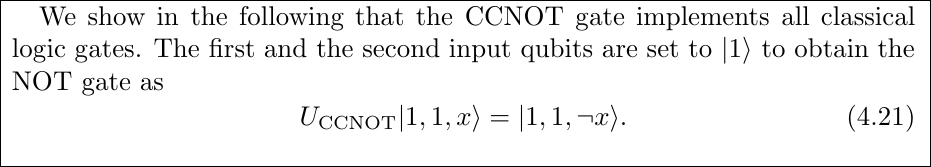

In [4]:
def not_using_ccnot(bit: int) -> int:
    if bit not in [0, 1]:
        raise ValueError("Input must be a classical bit (0 or 1)")

    # Prepare 3 bits state
    bits = "11" + str(bit)
    state = prepare_state(bits)

    output_state = CCNOT @ state

    result = read_state(output_state, 3)

    return int(result[-1])

In [5]:
print("Classical NOT using CCNOT:")
print(f"NOT 0 = {not_using_ccnot(0)}")
print(f"NOT 1 = {not_using_ccnot(1)}")

Classical NOT using CCNOT:
NOT 0 = 1
NOT 1 = 0


## XOR gate
- CNOT gate is quantum XOR
- Also can be used CCNOT to make XOR gate

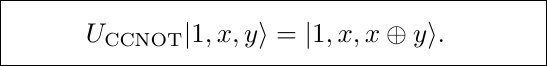

In [6]:
# Using CNOT gate

def xor_using_cnot(a: int, b: int) -> int:
    input_state = prepare_state(f"{a}{b}")
    output_state = CNOT @ input_state
    output_str = read_state(output_state, 2)
    return int(output_str[-1])

In [7]:
print("Classical XOR using CNOT:")
print(f"0 XOR 0 = {xor_using_cnot(0, 0)}")
print(f"0 XOR 1 = {xor_using_cnot(0, 1)}")
print(f"1 XOR 0 = {xor_using_cnot(1, 0)}")
print(f"1 XOR 1 = {xor_using_cnot(1, 1)}")

Classical XOR using CNOT:
0 XOR 0 = 0
0 XOR 1 = 1
1 XOR 0 = 1
1 XOR 1 = 0


In [8]:
def xor_using_ccnot(x: int, y: int) -> int:
    input_string = f"1{x}{y}"
    input_state = prepare_state(input_string)
    
    # Apply the CCNOT gate
    output_state = CCNOT @ input_state
    
    # Read the output state (e.g., "1, x, x xor y")
    out_str = read_state(output_state, 3)
    
    # The XOR result is the third qubit
    
    return int(out_str[-1])

In [9]:
print("XOR using CCNOT |1, x, y> -> |1, x, x ⊕ y>:")
print(f"0 XOR 0 = {xor_using_ccnot(0, 0)}")
print(f"0 XOR 1 = {xor_using_ccnot(0, 1)}")
print(f"1 XOR 0 = {xor_using_ccnot(1, 0)}")
print(f"1 XOR 1 = {xor_using_ccnot(1, 1)}")

XOR using CCNOT |1, x, y> -> |1, x, x ⊕ y>:
0 XOR 0 = 0
0 XOR 1 = 1
1 XOR 0 = 1
1 XOR 1 = 0


## AND gate

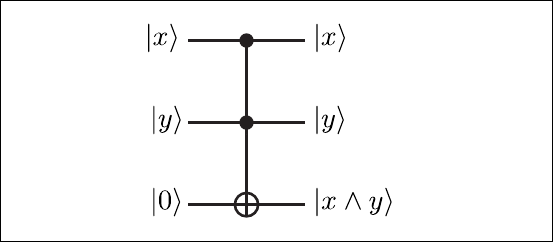

In [10]:
def and_using_ccnot(a: int, b: int) -> int:
    input_state = prepare_state(f"{a}{b}0")
    output_state = CCNOT @ input_state
    output_str = read_state(output_state, 3)
    return int(output_str[-1])

In [11]:
print("Classical AND using CCNOT:")
print(f"0 AND 0 = {and_using_ccnot(0, 0)}")
print(f"0 AND 1 = {and_using_ccnot(0, 1)}")
print(f"1 AND 0 = {and_using_ccnot(1, 0)}")
print(f"1 AND 1 = {and_using_ccnot(1, 1)}")

Classical AND using CCNOT:
0 AND 0 = 0
0 AND 1 = 0
1 AND 0 = 0
1 AND 1 = 1


## OR gate

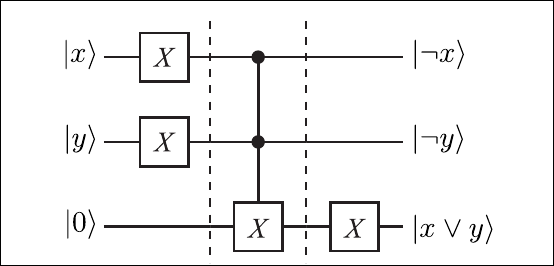

In [12]:
def or_gate(a: int, b: int) -> int:
    I1_state = prepare_state(f"{a}")
    I2_state = prepare_state(f"{b}")

    O1_state = X @ I1_state
    O2_state = X @ I2_state

    O1 = int(read_state(O1_state, 1))
    O2 = int(read_state(O2_state, 1))

    I3_state = prepare_state(f"{O1}{O2}0")

    O3_state = CCNOT @ I3_state
    O3 = read_state(O3_state, 3)

    I4_state = prepare_state(f"{O3[-1]}")
    O4_state = X @ I4_state

    result_str = read_state(O4_state, 1)
    return int(result_str[-1])

In [13]:
print("OR gate using CCNOT and X")
print(f"0 OR 0 = {or_gate(0, 0)}")
print(f"0 OR 1 = {or_gate(0, 1)}")
print(f"1 OR 0 = {or_gate(1, 0)}")
print(f"1 OR 1 = {or_gate(1, 1)}")

OR gate using CCNOT and X
0 OR 0 = 0
0 OR 1 = 1
1 OR 0 = 1
1 OR 1 = 1


In [14]:
# More easy way

X_Q0 = np.kron(np.kron(X, I), I)
X_Q1 = np.kron(np.kron(I, X), I)
X_Q2 = np.kron(np.kron(I, I), X)

def or_gate_quantum(a: int, b: int) -> int:
    # Prepare the 3-qubit system: |a, b, 0>
    state = prepare_state(f"{a}{b}0")
    
    # Apply X to Q0 and Q1
    state = X_Q0 @ state
    state = X_Q1 @ state
    
    # Apply CCNOT
    state = CCNOT @ state
    
    # Apply X to Q2 
    state = X_Q2 @ state
    
    # Read the final 3-qubit string and extract the last bit
    result_str = read_state(state, 3)
    return int(result_str[-1])

In [15]:
print("OR gate")
print(f"0 OR 0 = {or_gate(0, 0)}")
print(f"0 OR 1 = {or_gate(0, 1)}")
print(f"1 OR 0 = {or_gate(1, 0)}")
print(f"1 OR 1 = {or_gate(1, 1)}")

OR gate
0 OR 0 = 0
0 OR 1 = 1
1 OR 0 = 1
1 OR 1 = 1


## NAND gate

In [16]:
def nand_gate(a: int, b: int) -> int:
    I1_state = prepare_state(f"{a}{b}0")

    O1_state = CCNOT @ I1_state
    O1 = read_state(O1_state, 3)

    I2_state = prepare_state(f"{O1[-1]}")

    O2_state = X @ I2_state

    result_str = read_state(O2_state, 1)
    return int(result_str[-1])

In [17]:
print("Classical NAND gate")
print(f"0 NAND 0 = {nand_gate(0, 0)}") 
print(f"0 NAND 1 = {nand_gate(0, 1)}")
print(f"1 NAND 0 = {nand_gate(1, 0)}")
print(f"1 NAND 1 = {nand_gate(1, 1)}")

Classical NAND gate
0 NAND 0 = 1
0 NAND 1 = 1
1 NAND 0 = 1
1 NAND 1 = 0


In [18]:
# Alternatively using quantum native way

X_Q2 = np.kron(np.kron(I, I), X)

def nand_gate_quantum(a: int, b: int) -> int:
    # Prepare |a, b, 0>
    state = prepare_state(f"{a}{b}0")
    
    # Apply CCNOT, then X on Q2
    state = CCNOT @ state
    state = X_Q2 @ state
    
    # Read the final 3-qubit string and extract the last bit
    result_str = read_state(state, 3)
    return int(result_str[-1])


In [19]:
print("Classical NAND gate")
print(f"0 NAND 0 = {nand_gate(0, 0)}") 
print(f"0 NAND 1 = {nand_gate(0, 1)}")
print(f"1 NAND 0 = {nand_gate(1, 0)}")
print(f"1 NAND 1 = {nand_gate(1, 1)}")

Classical NAND gate
0 NAND 0 = 1
0 NAND 1 = 1
1 NAND 0 = 1
1 NAND 1 = 0
